# The Savitzky–Golay filter and complex signals

The Savitzky–Golay filter smooths noisy data by fitting a low-degree polynomial
to each window of samples, and it can also estimate derivatives of the data.
SciPy provides it as `scipy.signal.savgol_filter`.

This notebook shows a limitation of that function, reported in
[SciPy issue #19771](https://github.com/scipy/scipy/issues/19771): it does not
handle complex signals. It first shows the filter at work on a real signal, a
noisy sine wave, for both smoothing and derivatives. It then applies the same
filter to a complex signal, points on the unit circle, and shows that the
imaginary part is discarded, both when smoothing and when estimating
derivatives.

The notebook uses the released version of SciPy, so it shows the behaviour
before the fix. The fix was submitted in
[pull request #26784](https://github.com/scipy/scipy/pull/26784).


In [12]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.signal import savgol_filter

print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)

rng = np.random.default_rng(0)

NumPy version: 2.4.4
SciPy version: 1.17.1


## A first example: smoothing a noisy sine wave

To see what the Savitzky–Golay filter does, we start with a simple example where we know
the right answer. We take 200 evenly spaced points from the function $\sin(t)$, and add random noise to each of them, as if they were measurements. The plot
shows these noisy samples together with the sine function they were taken from, which is
the curve the filter should recover.

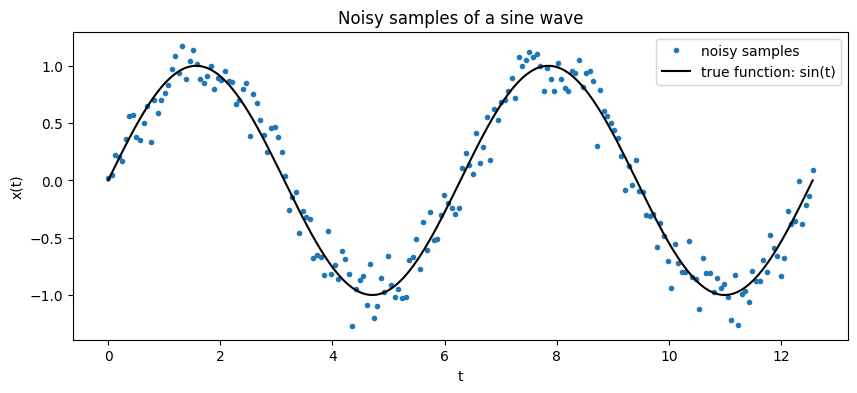

In [13]:
# Sample a sine wave at evenly spaced points and add noise
t = np.linspace(0, 4 * np.pi, 200)       # 200 sample points over two periods
x_true = np.sin(t)                       # the underlying function
noise = 0.15 * rng.standard_normal(t.size)
x_noisy = x_true + noise                 # what we actually "measure"

# A fine grid, only to draw the true sine as a smooth curve
t_fine = np.linspace(0, 4 * np.pi, 1000)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t, x_noisy, "o", ms=3, color="C0", label="noisy samples")
ax.plot(t_fine, np.sin(t_fine), "k-", lw=1.5, label="true function: sin(t)")
ax.set_xlabel("t")
ax.set_ylabel("x(t)")
ax.set_title("Noisy samples of a sine wave")
ax.legend()
plt.show()

Now we apply the Savitzky–Golay filter to the noisy samples. Around each point, the filter
takes a window of 21 neighbouring samples (`window_length`), fits a polynomial of degree 2
(`polyorder`) to them by least squares, and replaces the point with the value of that
polynomial at the centre of the window.

The result is again a set of 200 values, one for each original sample point, but with
much less noise. The plot shows these filtered points on top of the true sine function:
they lie close to the curve the noisy samples were taken from.

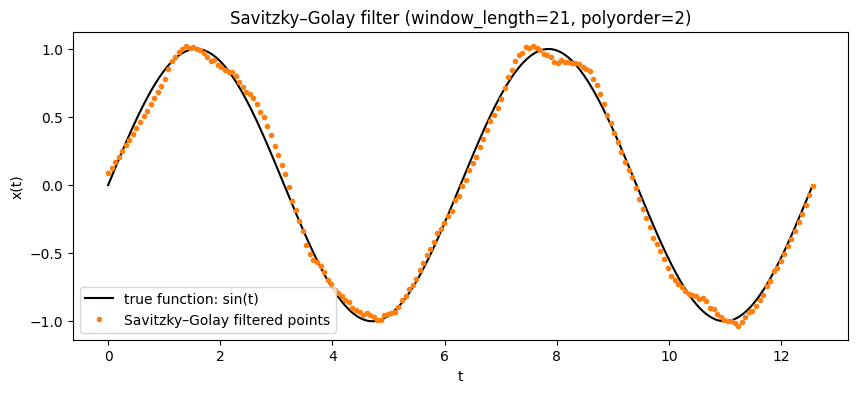

In [14]:
# Apply the Savitzky-Golay filter to the noisy samples
window_length = 21   # number of samples in each window (must be odd)
polyorder = 2        # degree of the polynomial fitted in each window

x_smooth = savgol_filter(x_noisy, window_length, polyorder)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t_fine, np.sin(t_fine), "k-", lw=1.5, label="true function: sin(t)")
ax.plot(t, x_smooth, "o", ms=3, color="C1", label="Savitzky–Golay filtered points")
ax.set_xlabel("t")
ax.set_ylabel("x(t)")
ax.set_title(f"Savitzky–Golay filter "
             f"(window_length={window_length}, polyorder={polyorder})")
ax.legend()
plt.show()

The same filter can also estimate derivatives. Instead of taking the value of the fitted
polynomial at the centre of each window, we take its first derivative (`deriv=1`). We
also pass the spacing between samples (`delta`), so that the result is the rate of change
per unit of $t$ rather than per sample.

Since the derivative of $\sin(t)$ is $\cos(t)$, the filtered points should lie on the
cosine curve. They follow it well, although they are noisier than the smoothed values,
because differentiating amplifies the noise that remains, and slightly less accurate at
the edges, where the derivative comes from a single polynomial fitted to the first (or
last) window.

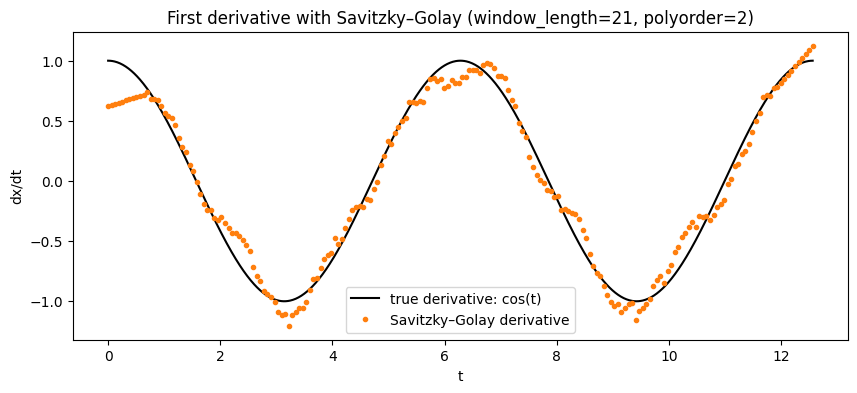

In [15]:
# First derivative with the Savitzky-Golay filter
dt = t[1] - t[0]   # spacing between samples, needed to get the derivative in units of t

dx_smooth = savgol_filter(x_noisy, window_length, polyorder, deriv=1, delta=dt)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t_fine, np.cos(t_fine), "k-", lw=1.5, label="true derivative: cos(t)")
ax.plot(t, dx_smooth, "o", ms=3, color="C1", label="Savitzky–Golay derivative")
ax.set_xlabel("t")
ax.set_ylabel("dx/dt")
ax.set_title(f"First derivative with Savitzky–Golay "
             f"(window_length={window_length}, polyorder={polyorder})")
ax.legend()
plt.show()

To see what the filter gains us, we can also compute the derivative directly
from the noisy samples, without filtering them first. A simple way to do this
is to take the difference between neighbouring samples and divide by their
spacing, which is what `np.gradient` does.

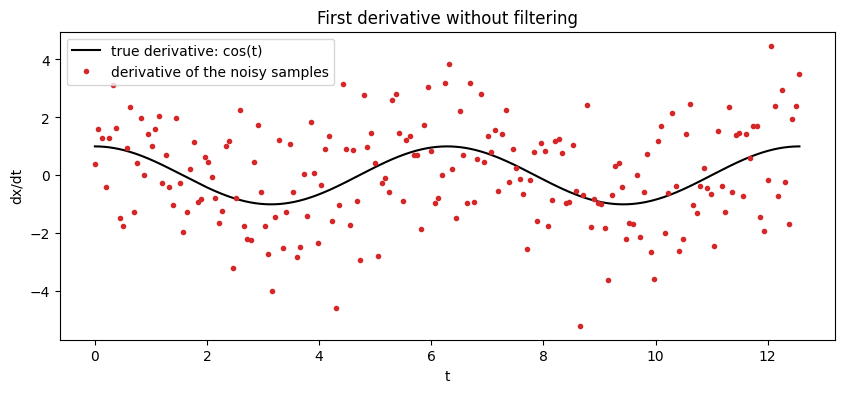

In [16]:
# Derivative of the noisy samples without any filtering:
# differences between neighbouring samples, divided by their spacing
dx_raw = np.gradient(x_noisy, dt)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t_fine, np.cos(t_fine), "k-", lw=1.5, label="true derivative: cos(t)")
ax.plot(t, dx_raw, "o", ms=3, color="C3", label="derivative of the noisy samples")
ax.set_xlabel("t")
ax.set_ylabel("dx/dt")
ax.set_title("First derivative without filtering")
ax.legend()
plt.show()

## What about complex signals?

So far the signal was real. Many signals, however, are complex: in physics,
for example, a quantum wave function is complex, and so are the signals
recorded by radios and radar. Since the Savitzky–Golay filter is just a
weighted sum of the samples with real weights, nothing in the method
requires the signal to be real: filtering a complex signal should give the
same result as filtering its real part and its imaginary part separately.

In the next cells we give `savgol_filter` a complex signal and check whether
this is what actually happens.

### A complex example: points on the unit circle

As a simple complex signal we take $z(t) = e^{it} = \cos t + i \sin t$,
sampled at the same 200 points as the sine wave. Its real part is $\cos t$
and its imaginary part is $\sin t$, and as $t$ grows the point $z(t)$ moves
around the unit circle in the complex plane. As before, we add noise, this
time independently to the real and the imaginary part of each sample.

The first plot shows the two parts separately, each with the function it was
taken from. The second shows the same noisy samples as points in the complex
plane, scattered around the unit circle that the filter should recover.

dtype of the signal: complex128


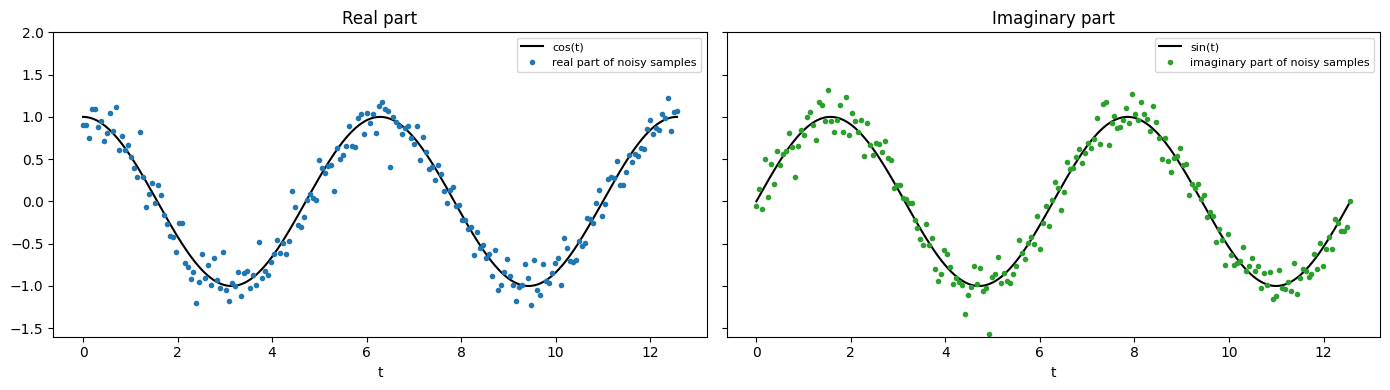

In [17]:
# A complex signal: points on the unit circle, z(t) = exp(i t) = cos(t) + i sin(t)
z_true = np.exp(1j * t)    # same 200 sample points t as before

# Add independent noise to the real and the imaginary part
noise_complex = 0.15 * (rng.standard_normal(t.size) + 1j * rng.standard_normal(t.size))
z_noisy = z_true + noise_complex

print("dtype of the signal:", z_noisy.dtype)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

ax1.plot(t_fine, np.cos(t_fine), "k-", lw=1.5, label="cos(t)")
ax1.plot(t, z_noisy.real, "o", ms=3, color="C0", label="real part of noisy samples")
ax1.set_title("Real part")

ax2.plot(t_fine, np.sin(t_fine), "k-", lw=1.5, label="sin(t)")
ax2.plot(t, z_noisy.imag, "o", ms=3, color="C2", label="imaginary part of noisy samples")
ax2.set_title("Imaginary part")

for ax in (ax1, ax2):
    ax.set_xlabel("t")
    ax.set_ylim(-1.6, 2.0)            # leave room at the top for the legend
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

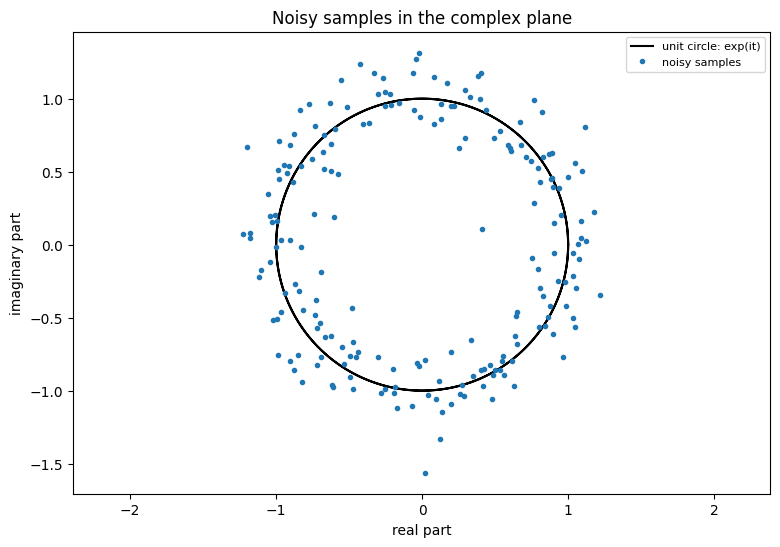

In [18]:
# The same noisy samples in the complex plane, on top of the unit circle
circle = np.exp(1j * t_fine)    # the exact circle, drawn on a fine grid

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(circle.real, circle.imag, "k-", lw=1.5, label="unit circle: exp(it)")
ax.plot(z_noisy.real, z_noisy.imag, "o", ms=3, color="C0", label="noisy samples")
ax.set_xlabel("real part")
ax.set_ylabel("imaginary part")
ax.set_title("Noisy samples in the complex plane")
ax.set_aspect("equal", adjustable="datalim")  # same scale on both axes: circle stays round
ax.legend(loc="upper right", fontsize=8)
plt.show()

### Filtering the complex signal

We now apply `savgol_filter` to the noisy complex samples, with the same
settings as for the sine wave, and plot the result: first in the complex
plane, then as real and imaginary parts.

When the filter runs, SciPy gives a warning: *ComplexWarning: Casting complex
values to real discards the imaginary part*. This tells us what happens to
our complex numbers: before filtering, `savgol_filter` converts its input to
real numbers, and in doing so it throws away the imaginary part. The
function then carries on as if nothing had happened.

The plots show the consequence. In the complex plane, the filtered points no
longer lie on the circle: they all fall on the real axis, because their
imaginary part is zero. Looking at the two parts separately, the real part
has been smoothed correctly and follows $\cos t$, but the imaginary part is
zero everywhere instead of following $\sin t$. The filter has done its job
on half of the signal and discarded the other half.

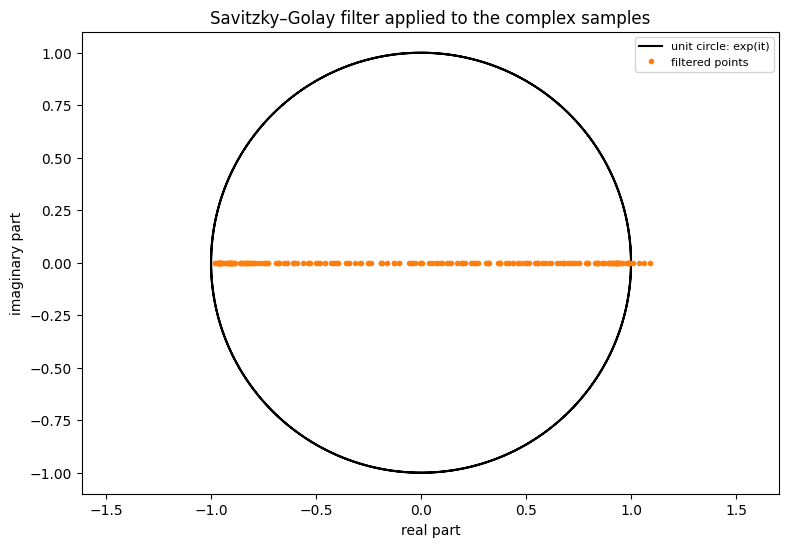

In [19]:
# Apply the Savitzky-Golay filter to the complex samples, with the same settings as before
z_smooth = savgol_filter(z_noisy, window_length, polyorder)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(circle.real, circle.imag, "k-", lw=1.5, label="unit circle: exp(it)")
ax.plot(z_smooth.real, z_smooth.imag, "o", ms=3, color="C1", label="filtered points")
ax.set_xlabel("real part")
ax.set_ylabel("imaginary part")
ax.set_title("Savitzky–Golay filter applied to the complex samples")
ax.set_aspect("equal", adjustable="datalim")  # same scale on both axes: circle stays round
ax.legend(loc="upper right", fontsize=8)
plt.show()

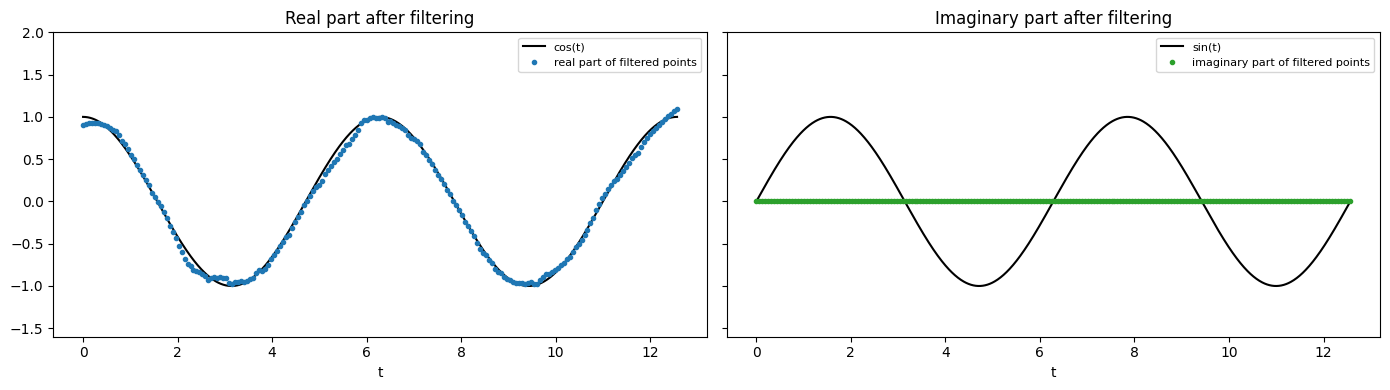

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

ax1.plot(t_fine, np.cos(t_fine), "k-", lw=1.5, label="cos(t)")
ax1.plot(t, z_smooth.real, "o", ms=3, color="C0", label="real part of filtered points")
ax1.set_title("Real part after filtering")

ax2.plot(t_fine, np.sin(t_fine), "k-", lw=1.5, label="sin(t)")
ax2.plot(t, z_smooth.imag, "o", ms=3, color="C2", label="imaginary part of filtered points")
ax2.set_title("Imaginary part after filtering")

for ax in (ax1, ax2):
    ax.set_xlabel("t")
    ax.set_ylim(-1.6, 2.0)            # leave room at the top for the legend
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

### The same problem for derivatives

The derivative of $z(t) = e^{it}$ is $z'(t) = i e^{it} = -\sin t + i \cos t$:
again a point moving around the unit circle, a quarter turn ahead of $z(t)$.
Its real part is $-\sin t$ and its imaginary part is $\cos t$.

We now estimate this derivative from the noisy samples with `savgol_filter`,
using `deriv=1` and the sample spacing `delta`, exactly as for the sine wave.
The same conversion happens before filtering, so the same problem appears:
the derivative of the real part, $-\sin t$, is estimated correctly, but the
imaginary part, which should follow $\cos t$, is zero everywhere. In the
complex plane the points again collapse onto the real axis.

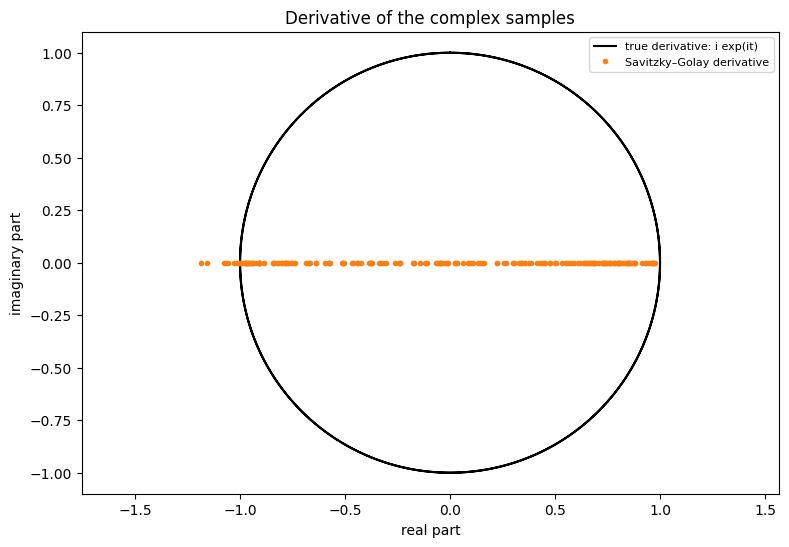

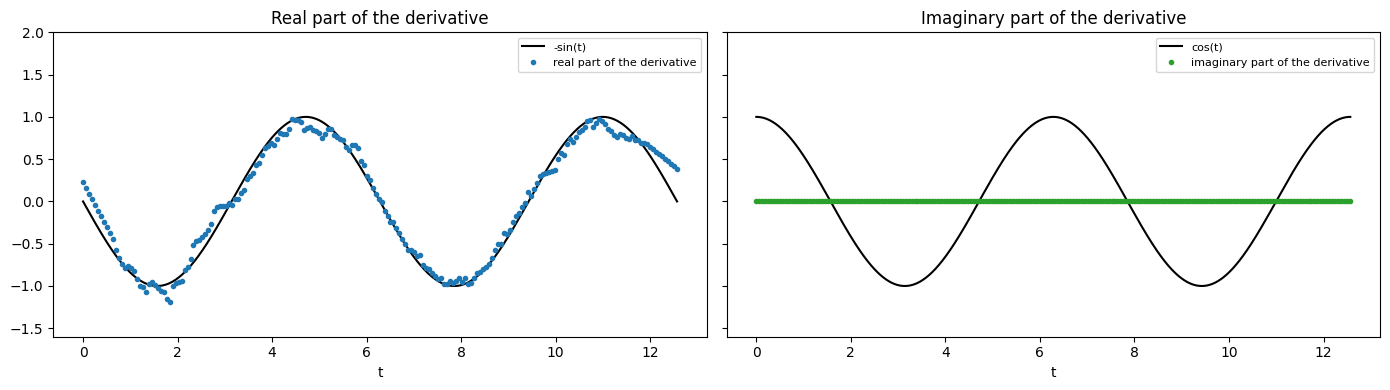

In [21]:
# First derivative of the complex samples, with the same settings as before
dz_smooth = savgol_filter(z_noisy, window_length, polyorder, deriv=1, delta=dt)

# The true derivative of exp(it) is i*exp(it) = -sin(t) + i cos(t): again the unit circle
dz_true_fine = 1j * np.exp(1j * t_fine)

# In the complex plane
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(dz_true_fine.real, dz_true_fine.imag, "k-", lw=1.5,
        label="true derivative: i exp(it)")
ax.plot(dz_smooth.real, dz_smooth.imag, "o", ms=3, color="C1",
        label="Savitzky–Golay derivative")
ax.set_xlabel("real part")
ax.set_ylabel("imaginary part")
ax.set_title("Derivative of the complex samples")
ax.set_aspect("equal", adjustable="datalim")  # same scale on both axes: circle stays round
ax.legend(loc="upper right", fontsize=8)
plt.show()

# Real and imaginary parts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

ax1.plot(t_fine, dz_true_fine.real, "k-", lw=1.5, label="-sin(t)")
ax1.plot(t, dz_smooth.real, "o", ms=3, color="C0", label="real part of the derivative")
ax1.set_title("Real part of the derivative")

ax2.plot(t_fine, dz_true_fine.imag, "k-", lw=1.5, label="cos(t)")
ax2.plot(t, dz_smooth.imag, "o", ms=3, color="C2", label="imaginary part of the derivative")
ax2.set_title("Imaginary part of the derivative")

for ax in (ax1, ax2):
    ax.set_xlabel("t")
    ax.set_ylim(-1.6, 2.0)            # leave room at the top for the legend
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

## Conclusion

For real signals, `savgol_filter` smooths the data and estimates its derivative
well. For complex signals, the released version converts the input to real
numbers before filtering, so the imaginary part is discarded, both when
smoothing and when estimating derivatives. The fix, submitted in
[pull request #26784](https://github.com/scipy/scipy/pull/26784), keeps complex
input as it is; a second notebook shows the fixed filter applied to a physical
example.